sudo apt install git-lfs for linux mint. Might need to download on other os aswell not shure

git lfs install
git lsf pull
wait for the images to download
unzip folders

run the following code
and then you are should have a folder "dataset_split" that has folders "train", "test", "val" that have folders 0,1,2,3,4,5

v3(no data aug): Test Loss: 0.2044713944196701
                 Test Accuracy: 0.9256198406219482

v4(no data aug): Test Loss: 0.2014741748571396
                 Test Accuracy: 0.939393937587738

In [17]:
from pathlib import Path
import random
import shutil

SEED = 0
rng = random.Random(SEED)

source = Path("kuvat")
target = Path("dataset_split")

#removes target if it exist and makes it again so that when this code is rerun with a different seed there will be no problems
if target.exists():
    shutil.rmtree(target)

target.mkdir(parents=True, exist_ok=True)

for class_dir in sorted(source.iterdir()):
    if not class_dir.is_dir():
        continue

    images = sorted(
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    rng.shuffle(images)

    n = len(images)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    splits = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:]
    }

    for split, files in splits.items():
        output_dir = target / split / class_dir.name
        output_dir.mkdir(parents=True, exist_ok=True)

        for file in files:
            shutil.copy2(file, output_dir / file.name)

        print(f"{class_dir.name} | {split}: {len(files)}")


.ipynb_checkpoints | train: 0
.ipynb_checkpoints | val: 0
.ipynb_checkpoints | test: 0
0 | train: 253
0 | val: 54
0 | test: 55
1 | train: 299
1 | val: 64
1 | test: 65
2 | train: 305
2 | val: 65
2 | test: 66
3 | train: 322
3 | val: 69
3 | test: 70
4 | train: 209
4 | val: 44
4 | test: 46
5 | train: 277
5 | val: 59
5 | test: 61


In [18]:
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    "dataset_split/train",
    image_size = (128, 128),
    batch_size = 32)
validation_dataset = image_dataset_from_directory(
    "dataset_split/val",
    image_size = (128, 128),
    batch_size = 32)
test_dataset = image_dataset_from_directory(
    "dataset_split/test",
    image_size = (128, 128),
    batch_size = 32,
    shuffle=False)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
])

Found 1665 files belonging to 6 classes.
Found 355 files belonging to 6 classes.
Found 363 files belonging to 6 classes.


In [19]:
inputs = keras.Input(shape=(128, 128, 3))

x = data_augmentation(inputs)

x = layers.Rescaling(1.0 / 255)(x)

x = layers.Conv2D(filters=32, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Dropout(0.2)(x)

x = layers.Conv2D(filters=64, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Dropout(0.2)(x)

x = layers.Conv2D(filters=128, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Dropout(0.2)(x)

x = layers.Conv2D(filters=256, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)


x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(6, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

#use_bias=False kun batch norm

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 389,958 (1.49 MB)

 Trainable params: 389,958 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
from tensorflow.keras.optimizers import Adam

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"],
)

history = model.fit(
    train_dataset,
    epochs=500,
    validation_data=validation_dataset,
)

Epoch 1/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 376ms/step - accuracy: 0.1814 - loss: 1.7928 - val_accuracy: 0.1944 - val_loss: 1.7876
Epoch 2/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 382ms/step - accuracy: 0.1616 - loss: 1.7855 - val_accuracy: 0.1944 - val_loss: 1.7807
Epoch 3/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 379ms/step - accuracy: 0.1772 - loss: 1.7881 - val_accuracy: 0.1944 - val_loss: 1.7850
Epoch 4/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 378ms/step - accuracy: 0.1940 - loss: 1.7837 - val_accuracy: 0.1944 - val_loss: 1.7820
Epoch 5/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 359ms/step - accuracy: 0.1910 - loss: 1.7839 - val_accuracy: 0.1944 - val_loss: 1.7828
Epoch 6/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 381ms/step - accuracy: 0.1916 - loss: 1.7838 - val_accuracy: 0.1944 - val_loss: 1.7829
Epoch 7/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 368ms/step - accuracy: 0.1982 - loss: 1.7848 - val_accuracy: 0.1944 - val_loss: 1.7830
Epoch 8/500
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 378ms/step - accuracy: 0.1676 - loss: 1.7840 - 

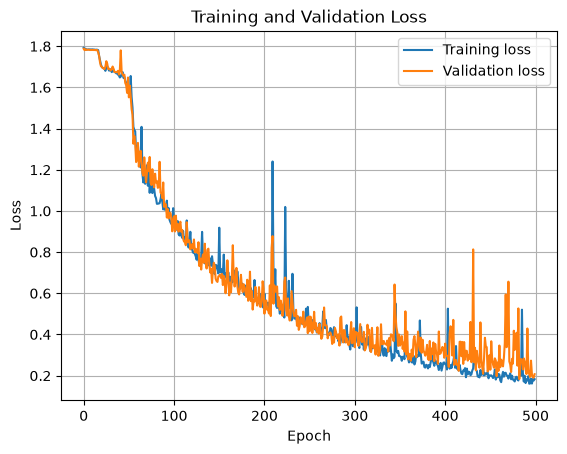

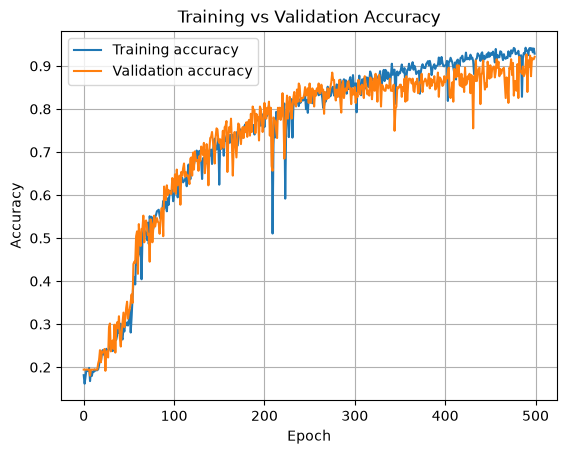

In [21]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()



12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.8953 - loss: 0.3226
Test Loss: 0.32263800501823425
Test Accuracy: 0.8953167796134949
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 173ms/step


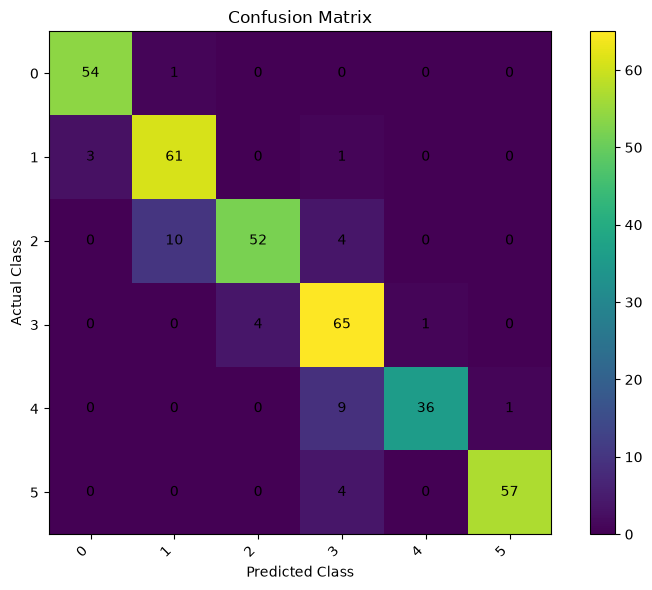

In [22]:
import numpy as np

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

#model.save("v4.keras")

#AI cm:
# True labels
y_true = np.concatenate([y.numpy() for x, y in test_dataset])

# Predicted labels
y_pred = np.argmax(model.predict(test_dataset), axis=1)

# Create confusion matrix
cm = np.zeros((6, 6), dtype=int)

for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

# Plot
plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.colorbar()

class_names = test_dataset.class_names

plt.xticks(range(6), class_names, rotation=45, ha='right')
plt.yticks(range(6), class_names)

for i in range(6):
    for j in range(6):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

Number of wrong predictions: 38


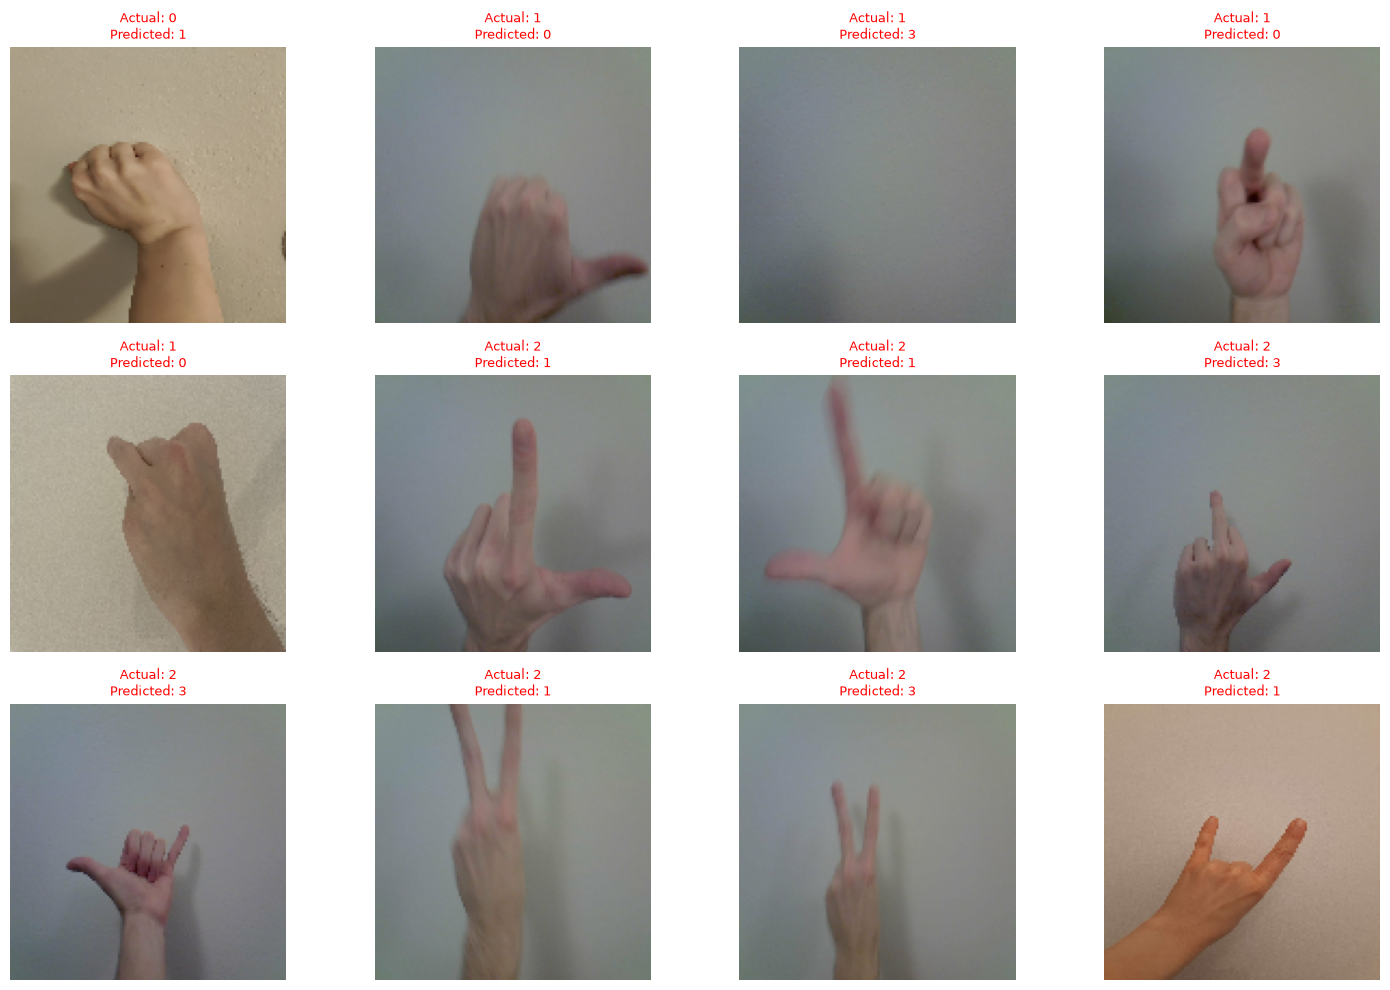

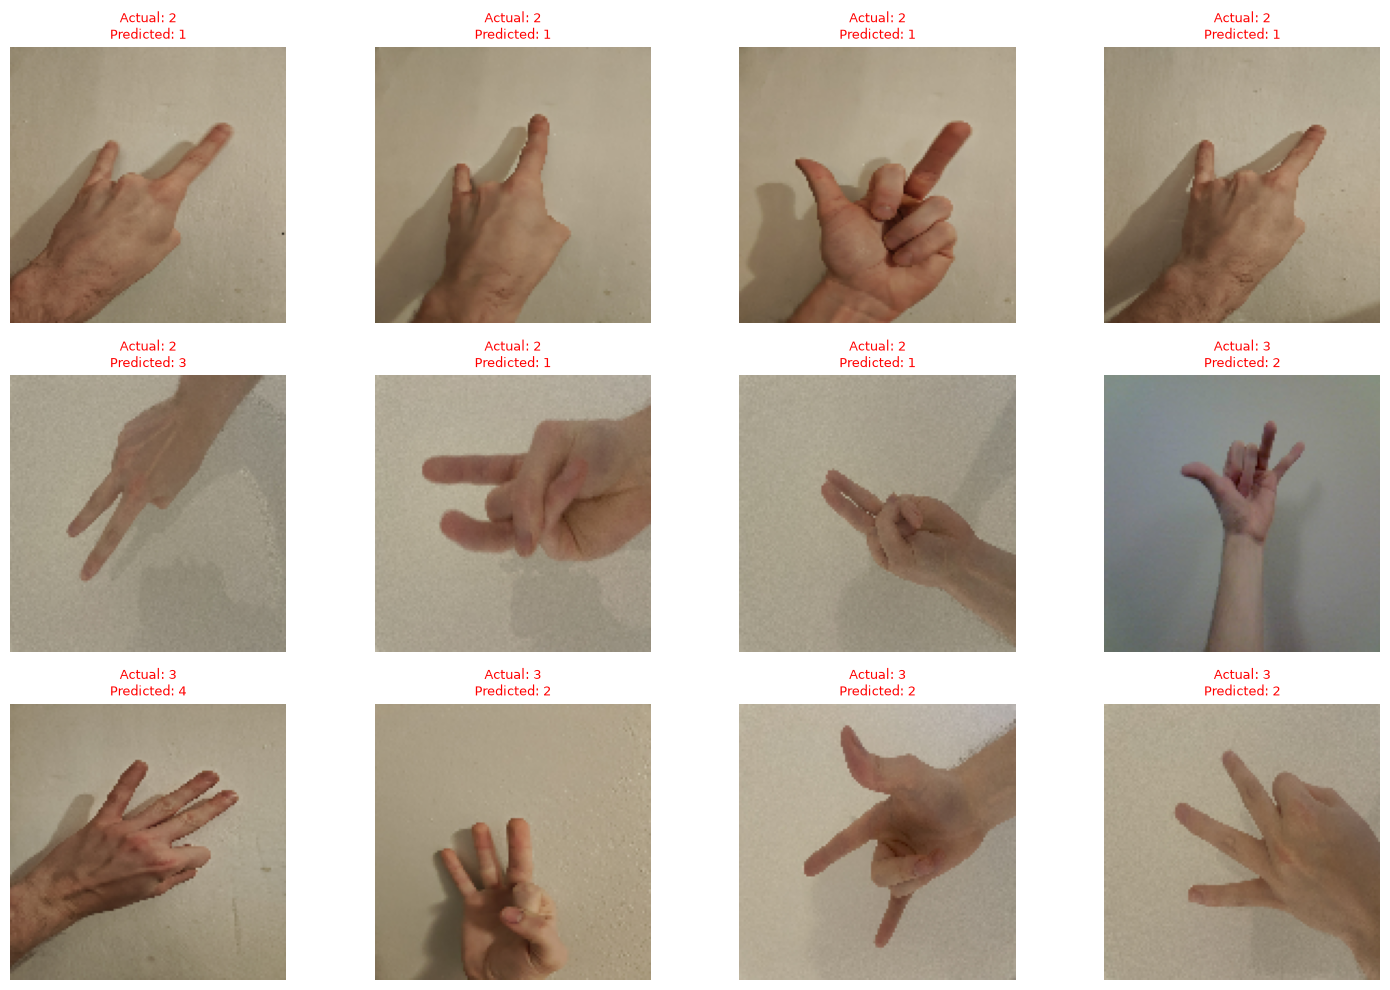

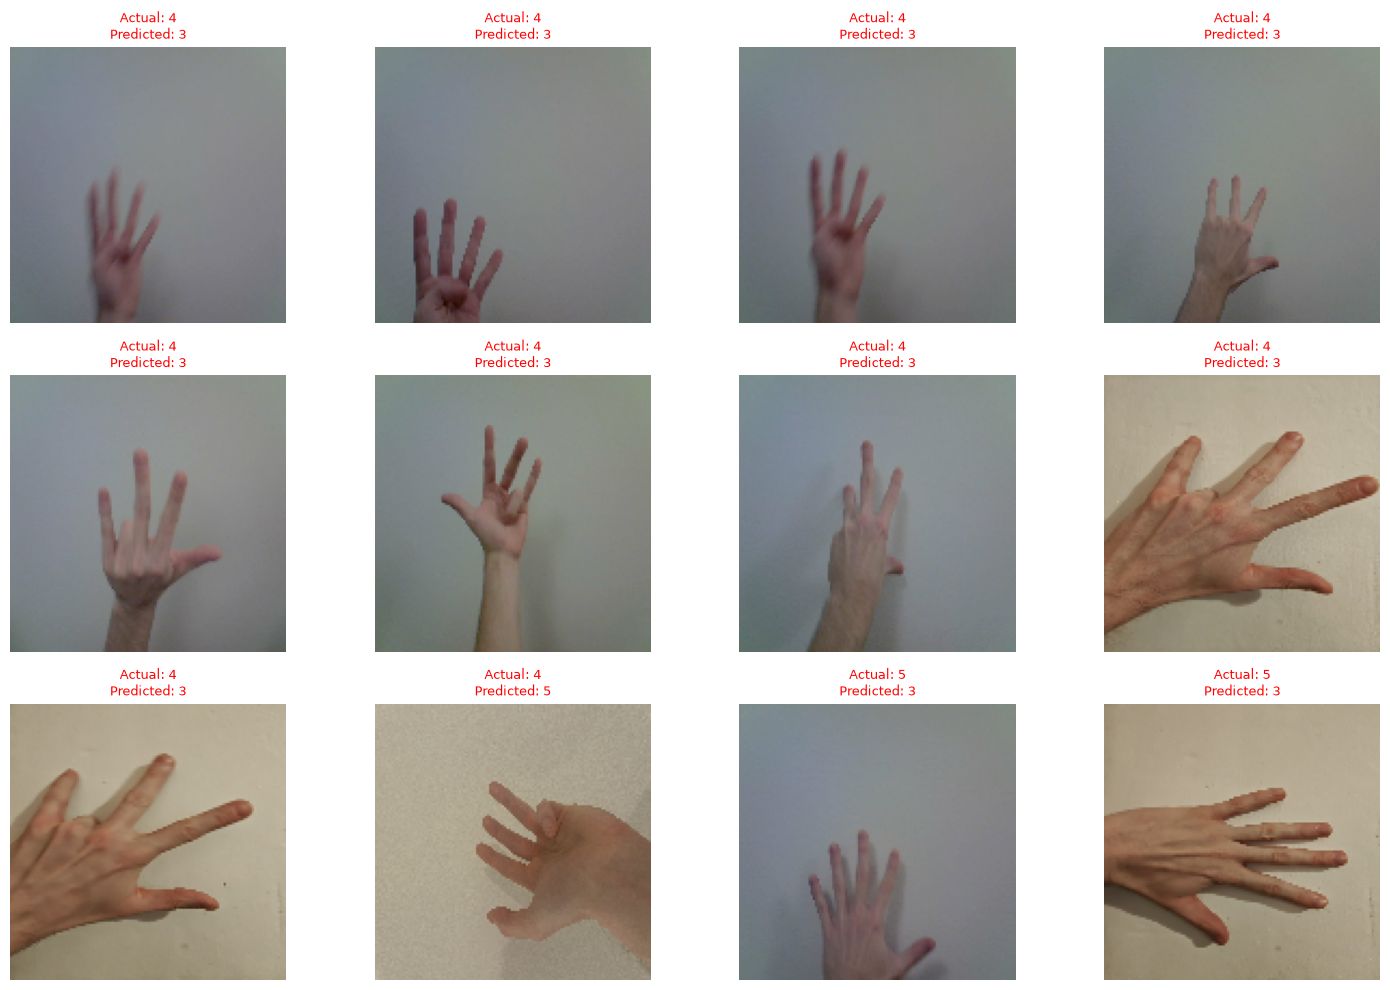

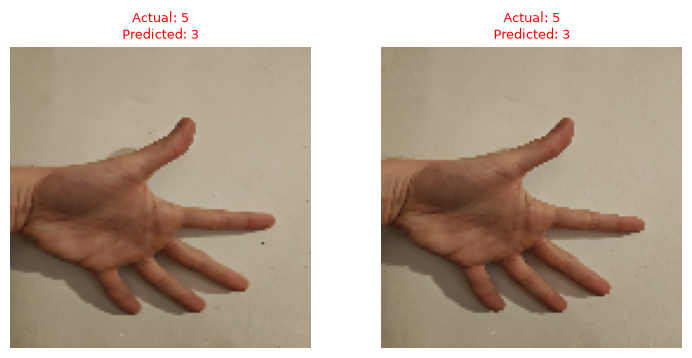

In [23]:
# Find wrongly classified images
wrong_indices = np.where(y_true != y_pred)[0]

print("Number of wrong predictions:", len(wrong_indices))

# Get all test images
X_test = np.concatenate([x.numpy() for x, y in test_dataset])

# Display wrong predictions
for start in range(0, len(wrong_indices), 12):

    batch_indices = wrong_indices[start:start + 12]

    plt.figure(figsize=(15, 10))

    for i, idx in enumerate(batch_indices):
        plt.subplot(3, 4, i + 1)

        plt.imshow(X_test[idx].astype("uint8"))

        plt.title(
            f"Actual: {class_names[y_true[idx]]}\n"
            f"Predicted: {class_names[y_pred[idx]]}",
            color='red',
            fontsize=9
        )

        plt.axis('off')

    plt.tight_layout()
    plt.show()